# 05 — Explainability with SHAP (FD001 and FD003)

Our models predict the RUL well, but for maintenance engineers a prediction is only useful if they can **trust** it. In this notebook we ask: **which sensors drive the predictions, and does that make engineering sense?**

We use **SHAP** on two models:
- the **Random Forest** (single cycle) with `TreeExplainer`;
- the **LSTM** (window of 30 cycles) with `GradientExplainer`.

We use two subsets with the **same single operating condition** but **different fault modes**:
- **FD001:** only HPC (high-pressure compressor) degradation;
- **FD003:** HPC degradation **and** fan degradation.

If the models are physically sensible, the important sensors should be different between the two subsets in a way that matches the fault modes.

## What SHAP does

SHAP (SHapley Additive exPlanations) splits **one prediction** into a contribution per input feature:

`prediction = base value + contribution(sensor 2) + contribution(sensor 3) + ... + contribution(sensor 21)`

- The **base value** is the average prediction over a reference ("background") dataset.
- A **negative** contribution means the sensor *pulls the predicted RUL down* (the engine looks more worn); a **positive** one pulls it up (healthier).
- The contributions are **Shapley values** from game theory: each feature gets its fair share of the difference between this prediction and the base value, averaged over all possible orders of adding the features.

To get a **global importance** per sensor we average the **absolute** contributions over many predictions (`mean |SHAP|`). A big value means the sensor often moves the prediction a lot.

**Two explainers:**
- `TreeExplainer` computes the **exact** Shapley values for tree models (fast, uses the tree structure).
- `GradientExplainer` works for neural networks. It uses **expected gradients**: it moves from background inputs to the input being explained and averages the gradients along the way. The result is an **approximation** of the Shapley values.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import torch
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from torch import nn

# Project root = parent of the "notebooks" folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data import FD001_SENSORS, SENSOR_DESCRIPTIONS, sensor_label
from src.metrics import nasa_score, rmse
from src.models import LSTMModel
from src.pipeline import prepare_subset
from src.training import predict, set_seed, train_model

FIG_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIG_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 0
RUL_CAP = 125
WINDOW_SIZE = 30
SUBSETS = ["FD001", "FD003"]

# Readable labels for the plots, e.g. "s11 Ps30"
LABELS = [sensor_label(s) for s in FD001_SENSORS]

# SHAP's plots print a FutureWarning about NumPy's random generator; it does not affect the results
warnings.filterwarnings("ignore", category=FutureWarning)

## 1. What the 14 sensors measure

A turbofan, from front to back: **fan → LPC** (low-pressure compressor) **→ HPC** (high-pressure compressor) **→ combustor → HPT** (high-pressure turbine) **→ LPT** (low-pressure turbine). Part of the air from the fan bypasses the core (the *bypass* flow). The table lists the 14 sensors we use, with their symbol and meaning (Saxena et al., 2008).

In [2]:
sensor_table = pd.DataFrame(
    [(s, SENSOR_DESCRIPTIONS[s][0], SENSOR_DESCRIPTIONS[s][1]) for s in FD001_SENSORS],
    columns=["sensor", "symbol", "meaning"],
).set_index("sensor")
sensor_table

,symbol,meaning
sensor,,
sensor_2,T24,Total temperature at LPC outlet
sensor_3,T30,Total temperature at HPC outlet
sensor_4,T50,Total temperature at LPT outlet
sensor_7,P30,Total pressure at HPC outlet
sensor_8,Nf,Physical fan speed
sensor_9,Nc,Physical core speed
sensor_11,Ps30,Static pressure at HPC outlet
sensor_12,phi,Ratio of fuel flow to Ps30
sensor_13,NRf,Corrected fan speed


**What we expect from physics:**
- **HPC degradation** (FD001 and FD003): the compressor loses efficiency, so to deliver the same thrust the engine runs **hotter** and the core works harder. We expect the HPC outlet sensors (`T30` s3, `P30` s7, `Ps30` s11), the downstream temperature `T50` (s4), the fuel-flow ratio `phi` (s12) and the core speed (`Nc` s9, `NRc` s14) to matter.
- **Fan degradation** (only FD003): the fan loses efficiency and changes the bypass flow. We expect the **fan speeds** (`Nf` s8, `NRf` s13) and the **bypass ratio** `BPR` (s15) to become more important in FD003 than in FD001.

## 2. Train the models

We use the pipeline of `04` (`prepare_subset` in `src/pipeline.py`): RUL capped at 125, split by engine, sensors normalized on the training engines, windows of 30 cycles. Here we use **all** training windows (stride 1) and the `03` training settings (patience 10), since we only train 2 LSTMs. One seed (0) is enough: we want to explain a model, not compare models.

We check the test RMSE to make sure the models we explain are as good as in `04`.

In [3]:
data = {}
rf_models = {}
lstm_models = {}

for subset in SUBSETS:
    data[subset] = prepare_subset(subset, window_size=WINDOW_SIZE, rul_cap=RUL_CAP, train_stride=1)
    d = data[subset]

    # Random Forest on single cycles (as in 02 and 04)
    rf = RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)
    rf.fit(d["train_part"][FD001_SENSORS], d["train_part"]["RUL"])
    rf_models[subset] = rf

    # LSTM on windows (as in 03)
    set_seed(SEED)
    lstm = LSTMModel(n_features=len(FD001_SENSORS))
    lstm, _ = train_model(lstm, d["X_train"], d["y_train"] / RUL_CAP, d["X_val"], d["y_val"] / RUL_CAP,
                          seed=SEED, verbose=False)
    lstm_models[subset] = lstm

    rf_pred = rf.predict(d["X_test_rf"])
    lstm_pred = predict(lstm, d["X_test"]) * RUL_CAP
    print(f"{subset}: Random Forest RMSE {rmse(d['y_test'], rf_pred):.2f} | "
          f"LSTM RMSE {rmse(d['y_test'], lstm_pred):.2f}")

FD001: Random Forest RMSE 17.62 | LSTM RMSE 15.14


FD003: Random Forest RMSE 21.42 | LSTM RMSE 16.26


## 3. Which samples do we explain?

We explain the predictions on the **100 test engines** of each subset (last cycle for the Random Forest, last 30-cycle window for the LSTM). These are exactly the predictions we evaluated with RMSE and the NASA score.

**Reference ("background") for the base value:**
- **Random Forest:** `TreeExplainer` needs no background data. Each tree remembers how many training samples went down each branch, and SHAP uses these counts as the reference. The base value is then the average prediction over the training data. This is exact and fast.
- **LSTM:** `GradientExplainer` needs explicit background inputs. We use a random sample of **200 training windows**, which keeps SHAP fast on a laptop CPU.

## 4. Random Forest: TreeExplainer

`TreeExplainer` gives one SHAP value per test engine and sensor (shape 100 × 14). For a Random Forest with full-depth trees this takes about 30 seconds per subset.

**Check:** SHAP values are additive, so `base value + sum of SHAP values` must equal the prediction of the model.

In [4]:
rf_shap = {}

for subset in SUBSETS:
    d = data[subset]
    # No background data: the reference comes from the training samples stored in the trees
    explainer = shap.TreeExplainer(rf_models[subset])
    rf_shap[subset] = explainer.shap_values(d["X_test_rf"])

    # Additivity check (expected_value is an array with 1 element: take that element)
    base_value = np.ravel(explainer.expected_value)[0]
    reconstructed = base_value + rf_shap[subset].sum(axis=1)
    max_error = np.abs(reconstructed - rf_models[subset].predict(d["X_test_rf"])).max()
    print(f"{subset}: SHAP shape {rf_shap[subset].shape}, base value {base_value:.1f}, "
          f"max additivity error {max_error:.4f} cycles")

FD001: SHAP shape (100, 14), base value 86.9, max additivity error 0.0000 cycles


FD003: SHAP shape (100, 14), base value 93.5, max additivity error 0.0000 cycles


The **beeswarm plot** shows every test engine as a dot, for each sensor. The x-position is the SHAP value (effect on the predicted RUL, in cycles) and the colour is the sensor value (red = high, blue = low, after normalization). Sensors are sorted by importance.

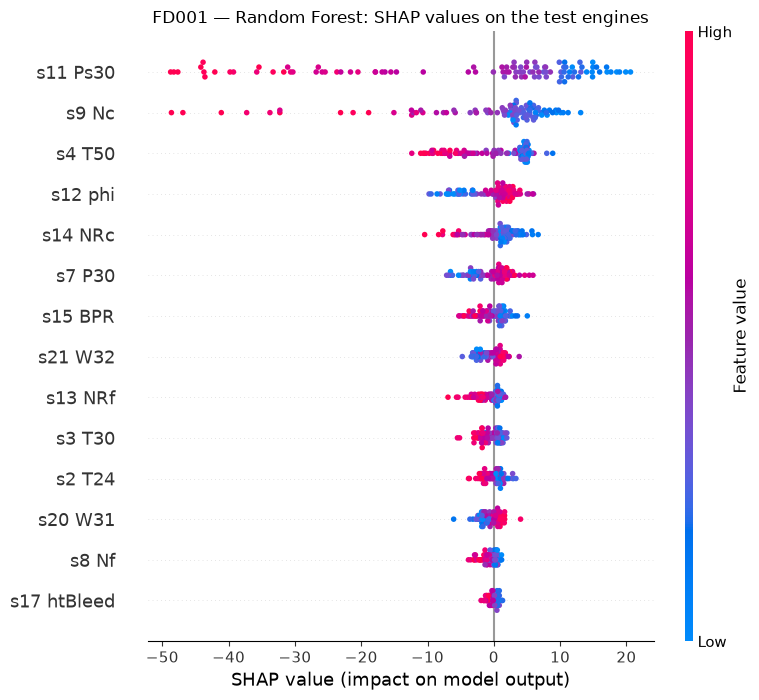

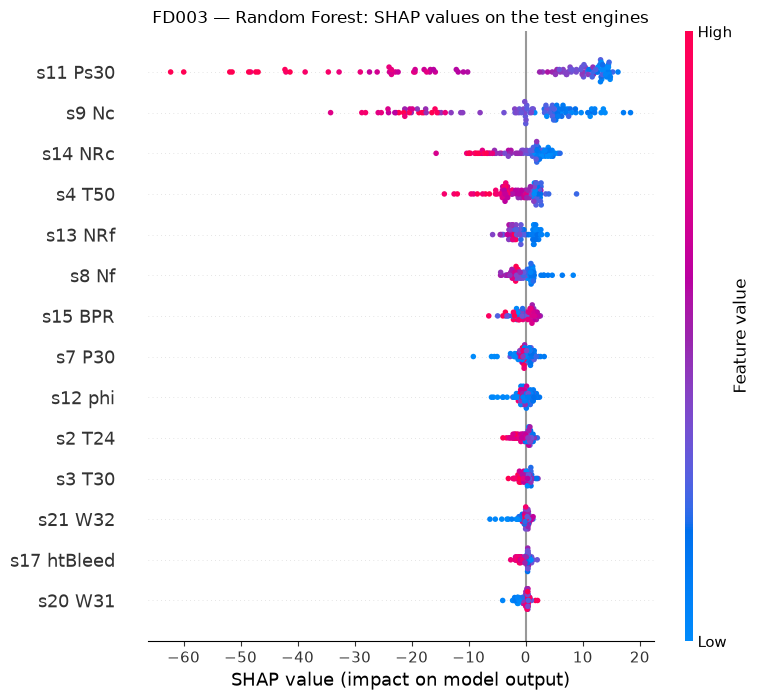

In [5]:
for subset in SUBSETS:
    shap.summary_plot(rf_shap[subset], data[subset]["X_test_rf"], feature_names=LABELS, show=False)
    plt.title(f"{subset} — Random Forest: SHAP values on the test engines")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"05_rf_beeswarm_{subset.lower()}.png", dpi=150)
    plt.show()

How to read it: for a sensor where **red dots are on the left**, a *high* value *lowers* the predicted RUL (it is a sign of wear); for a sensor where **blue dots are on the left**, a *low* value is the sign of wear. This matches the trends we saw in `01_eda`: e.g. `Ps30` (s11) increases and `W31`/`W32` (s20, s21) decrease near failure.

## 5. LSTM: GradientExplainer

### A small wrapper

`GradientExplainer` expects a model whose output has shape *(batch, number of outputs)*. Our LSTM returns shape *(batch,)*, one number per window. The wrapper below only adds that missing dimension; it does not change the predictions.

In [6]:
class AddOutputDimension(nn.Module):
    """Wrap a model so that its output has shape (batch, 1) instead of (batch,)."""

    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        return self.model(x).unsqueeze(-1)

### SHAP values over the window

For the LSTM the input of one prediction is a **30 × 14** window, so SHAP gives one value **per cycle and per sensor**: shape (100 engines, 30 cycles, 14 sensors).

The LSTM predicts on the 0–1 scale (RUL / 125), so we multiply the SHAP values by 125 to get them in **cycles**, like for the Random Forest.

We then aggregate in two ways:
1. **Per sensor:** for each engine we **add up** a sensor's SHAP values over the 30 cycles. This is the total effect of that sensor on the prediction (thanks to additivity). Then we take the mean of the absolute value over the engines, as for the Random Forest.
2. **Per position in the window:** for each cycle position (1 = oldest, 30 = most recent) we take the mean absolute SHAP value, summed over the sensors. This shows **which part of the window** the LSTM looks at.

`GradientExplainer` uses random sampling, so we fix the NumPy and PyTorch seeds before running it.

In [7]:
lstm_shap = {}       # shape (engines, 30, 14), in cycles
lstm_base = {}

for subset in SUBSETS:
    d = data[subset]
    rng = np.random.default_rng(SEED)
    background_idx = rng.choice(len(d["X_train"]), size=200, replace=False)
    background = torch.from_numpy(d["X_train"][background_idx])

    model = AddOutputDimension(lstm_models[subset]).eval()
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    explainer = shap.GradientExplainer(model, background)
    values = explainer.shap_values(torch.from_numpy(d["X_test"]))   # (100, 30, 14, 1)
    lstm_shap[subset] = values[..., 0] * RUL_CAP

    # Approximate additivity check: base value + sum of SHAP values ≈ prediction
    with torch.no_grad():
        lstm_base[subset] = model(background).mean().item() * RUL_CAP
    reconstructed = lstm_base[subset] + lstm_shap[subset].sum(axis=(1, 2))
    prediction = predict(lstm_models[subset], d["X_test"]) * RUL_CAP
    error = np.abs(reconstructed - prediction)
    print(f"{subset}: SHAP shape {lstm_shap[subset].shape}, base value {lstm_base[subset]:.1f}, "
          f"additivity error: mean {error.mean():.1f}, max {error.max():.1f} cycles")

FD001: SHAP shape (100, 30, 14), base value 80.6, additivity error: mean 2.9, max 9.5 cycles


FD003: SHAP shape (100, 30, 14), base value 94.2, additivity error: mean 3.4, max 14.0 cycles


For the LSTM the additivity holds only **approximately**: expected gradients is an estimate based on 200 background windows. The error is about 3 cycles on average but up to 10–14 cycles for some engines. That is good enough to **rank the sensors over 100 engines**, but we should not over-interpret the exact SHAP values of a single engine. A larger background would reduce the error, at the cost of more computation.

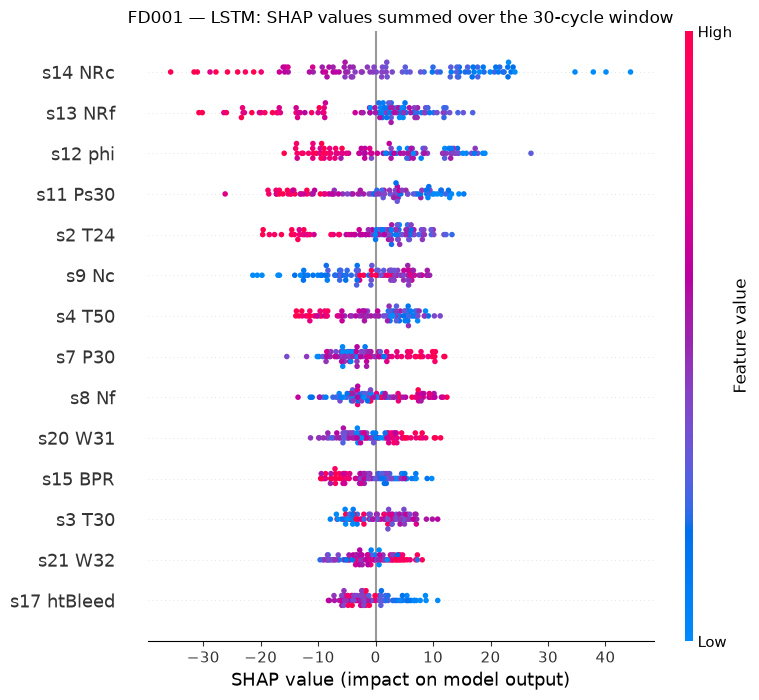

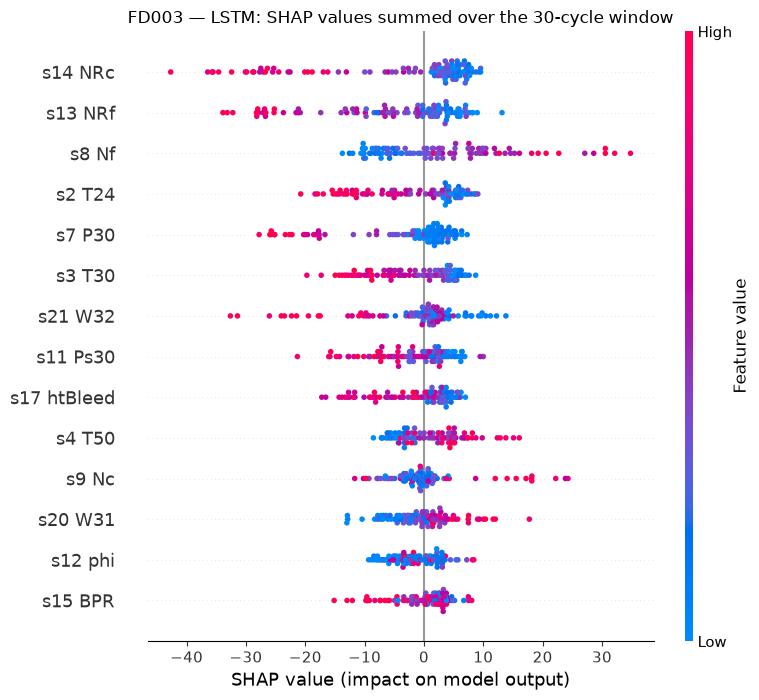

In [8]:
# Per sensor: sum over the 30 cycles, then mean absolute value over engines
lstm_sensor_shap = {subset: lstm_shap[subset].sum(axis=1) for subset in SUBSETS}   # (engines, 14)

for subset in SUBSETS:
    # Colour = mean normalized sensor value over the window
    window_means = data[subset]["X_test"].mean(axis=1)
    shap.summary_plot(lstm_sensor_shap[subset], window_means, feature_names=LABELS, show=False)
    plt.title(f"{subset} — LSTM: SHAP values summed over the 30-cycle window")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"05_lstm_beeswarm_{subset.lower()}.png", dpi=150)
    plt.show()

### How importance changes across the window

Left: total importance per cycle position (mean |SHAP| summed over sensors). Right: a heatmap of mean |SHAP| per sensor (rows) and cycle position (columns), for FD001.

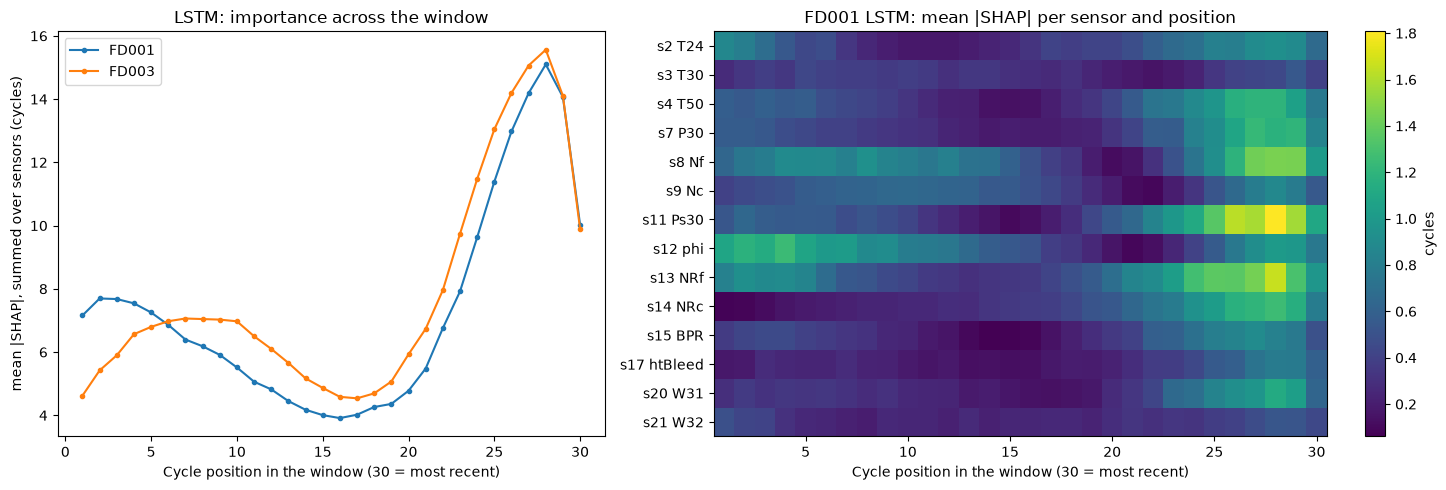

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.4]})

positions = np.arange(1, WINDOW_SIZE + 1)
for subset in SUBSETS:
    importance_per_step = np.abs(lstm_shap[subset]).mean(axis=0).sum(axis=1)   # (30,)
    axes[0].plot(positions, importance_per_step, marker="o", markersize=3, label=subset)
axes[0].set_xlabel("Cycle position in the window (30 = most recent)")
axes[0].set_ylabel("mean |SHAP|, summed over sensors (cycles)")
axes[0].set_title("LSTM: importance across the window")
axes[0].legend()

heatmap = np.abs(lstm_shap["FD001"]).mean(axis=0).T   # (14 sensors, 30 positions)
image = axes[1].imshow(heatmap, aspect="auto", cmap="viridis",
                       extent=[0.5, WINDOW_SIZE + 0.5, len(LABELS) - 0.5, -0.5])
axes[1].set_yticks(range(len(LABELS)))
axes[1].set_yticklabels(LABELS)
axes[1].set_xlabel("Cycle position in the window (30 = most recent)")
axes[1].set_title("FD001 LSTM: mean |SHAP| per sensor and position")
fig.colorbar(image, ax=axes[1], label="cycles")

plt.tight_layout()
plt.savefig(FIG_DIR / "05_lstm_importance_over_window.png", dpi=150)
plt.show()

In [10]:
# How much of the total importance is in the last 10 cycles of the window?
for subset in SUBSETS:
    per_step = np.abs(lstm_shap[subset]).mean(axis=0).sum(axis=1)
    share_last_10 = per_step[-10:].sum() / per_step.sum()
    print(f"{subset}: last 10 cycles = {share_last_10:.0%} of the importance "
          f"(would be 33% if all positions mattered equally)")

FD001: last 10 cycles = 49% of the importance (would be 33% if all positions mattered equally)
FD003: last 10 cycles = 50% of the importance (would be 33% if all positions mattered equally)


## 6. Do the Random Forest and the LSTM agree?

To compare the two models on the same scale, we **normalize** each importance vector so that it sums to 1 (share of total importance). We then compare:
- the **Spearman rank correlation** of the two rankings (1 = same order, 0 = unrelated);
- the **overlap of the top 5** sensors.

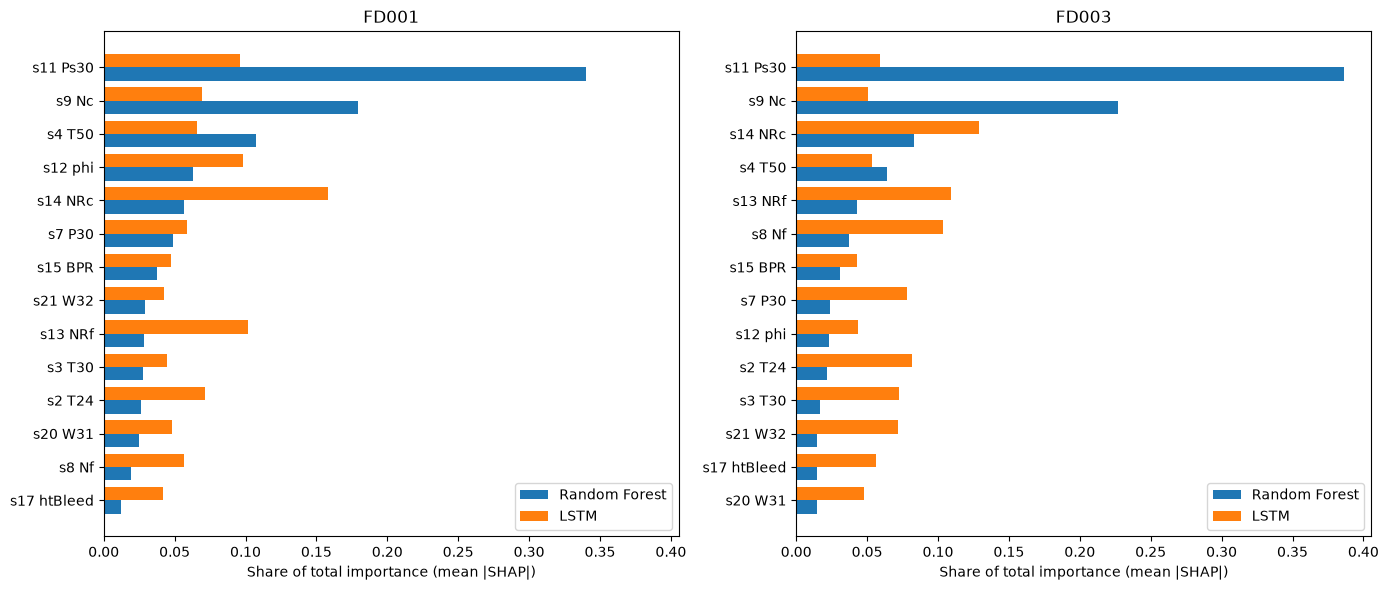

In [11]:
importance_rows = []
for subset in SUBSETS:
    rf_importance = np.abs(rf_shap[subset]).mean(axis=0)
    lstm_importance = np.abs(lstm_sensor_shap[subset]).mean(axis=0)
    for sensor, label, rf_value, lstm_value in zip(FD001_SENSORS, LABELS, rf_importance, lstm_importance):
        importance_rows.append({"subset": subset, "sensor": sensor, "label": label,
                                "RF": rf_value, "LSTM": lstm_value})

importance = pd.DataFrame(importance_rows)
# Share of the total importance of each model and subset
for model in ["RF", "LSTM"]:
    importance[f"{model}_share"] = importance[model] / importance.groupby("subset")[model].transform("sum")
importance.to_csv(METRICS_DIR / "05_shap_importance.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
for ax, subset in zip(axes, SUBSETS):
    table = importance[importance["subset"] == subset].sort_values("RF_share")
    y = np.arange(len(table))
    ax.barh(y - 0.2, table["RF_share"], height=0.4, label="Random Forest")
    ax.barh(y + 0.2, table["LSTM_share"], height=0.4, label="LSTM")
    ax.set_yticks(y)
    ax.set_yticklabels(table["label"])
    ax.set_xlabel("Share of total importance (mean |SHAP|)")
    ax.set_title(subset)
    ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_rf_vs_lstm_importance.png", dpi=150)
plt.show()

In [12]:
agreement_rows = []
for subset in SUBSETS:
    table = importance[importance["subset"] == subset]
    top5_rf = table.nlargest(5, "RF")["label"].tolist()
    top5_lstm = table.nlargest(5, "LSTM")["label"].tolist()
    correlation, _ = spearmanr(table["RF"], table["LSTM"])
    agreement_rows.append({
        "subset": subset,
        "Spearman rank correlation": round(correlation, 2),
        "top 5 Random Forest": ", ".join(top5_rf),
        "top 5 LSTM": ", ".join(top5_lstm),
        "common in top 5": len(set(top5_rf) & set(top5_lstm)),
    })

pd.DataFrame(agreement_rows).set_index("subset").T

subset,FD001,FD003
Spearman rank correlation,0.53,0.19
top 5 Random Forest,"s11 Ps30, s9 Nc, s4 T50, s12 phi, s14 NRc","s11 Ps30, s9 Nc, s14 NRc, s4 T50, s13 NRf"
top 5 LSTM,"s14 NRc, s13 NRf, s12 phi, s11 Ps30, s2 T24","s14 NRc, s13 NRf, s8 Nf, s2 T24, s7 P30"
common in top 5,3,2


### Correlated sensor pairs

Some sensors measure almost the same thing:
- `Nc` (s9, physical core speed) and `NRc` (s14, corrected core speed);
- `Nf` (s8, physical fan speed) and `NRf` (s13, corrected fan speed).

A *corrected* speed is the physical speed adjusted for the inlet temperature. With a single operating condition the inlet temperature is constant, so the two are strongly correlated:

In [13]:
for subset in SUBSETS:
    d = data[subset]["train_part"]
    print(f"{subset}: correlation Nc–NRc = {d['sensor_9'].corr(d['sensor_14']):.2f} | "
          f"Nf–NRf = {d['sensor_8'].corr(d['sensor_13']):.2f}")

FD001: correlation Nc–NRc = 0.97 | Nf–NRf = 0.83
FD003: correlation Nc–NRc = 0.95 | Nf–NRf = 0.96


When two inputs carry the same information, a model can use either of them, or both, and SHAP splits the credit between them in a somewhat arbitrary way. The Random Forest prefers `Nc`, the LSTM prefers `NRc`, so the rankings above look more different than they really are. The FD003 LSTM beeswarm even shows **opposite signs** inside a pair (a high `Nf` raises the predicted RUL, a high `NRf` lowers it): the LSTM uses the small *difference* between the two.

So we also compare the models after **merging each pair into one group**. Because SHAP values are additive, the SHAP value of a group is the **sum** of the SHAP values of its sensors (per engine), and then we take the mean absolute value as before.

In [14]:
# Each group is a list of sensors; the two speed pairs are merged, every other sensor is on its own
GROUPS = {"Core speed (s9 Nc + s14 NRc)": ["sensor_9", "sensor_14"],
          "Fan speed (s8 Nf + s13 NRf)": ["sensor_8", "sensor_13"]}
for sensor, label in zip(FD001_SENSORS, LABELS):
    if sensor not in ["sensor_9", "sensor_14", "sensor_8", "sensor_13"]:
        GROUPS[label] = [sensor]


def group_importance(shap_values):
    """shap_values: (engines, 14) -> share of total importance of each group."""
    result = {}
    for group, sensors in GROUPS.items():
        columns = [FD001_SENSORS.index(s) for s in sensors]
        group_shap = shap_values[:, columns].sum(axis=1)   # additive: sum within the group
        result[group] = np.abs(group_shap).mean()
    result = pd.Series(result)
    return result / result.sum()


grouped_rows = []
grouped_tables = {}
for subset in SUBSETS:
    table = pd.DataFrame({
        "RF": group_importance(rf_shap[subset]),
        "LSTM": group_importance(lstm_sensor_shap[subset]),
    }).sort_values("RF", ascending=False)
    grouped_tables[subset] = table
    correlation, _ = spearmanr(table["RF"], table["LSTM"])
    top3_rf = table["RF"].nlargest(3).index.tolist()
    top3_lstm = table["LSTM"].nlargest(3).index.tolist()
    grouped_rows.append({
        "subset": subset,
        "Spearman rank correlation": round(correlation, 2),
        "top 3 Random Forest": ", ".join(top3_rf),
        "top 3 LSTM": ", ".join(top3_lstm),
        "common in top 3": len(set(top3_rf) & set(top3_lstm)),
    })

display(pd.DataFrame(grouped_rows).set_index("subset").T)
for subset in SUBSETS:
    print(f"{subset}: share of importance per group (%)")
    display((grouped_tables[subset] * 100).round(1))

subset,FD001,FD003
Spearman rank correlation,0.74,0.26
top 3 Random Forest,"s11 Ps30, Core speed (s9 Nc + s14 NRc), s4 T50","s11 Ps30, Core speed (s9 Nc + s14 NRc), Fan sp..."
top 3 LSTM,"Core speed (s9 Nc + s14 NRc), s12 phi, s11 Ps30","Core speed (s9 Nc + s14 NRc), s2 T24, Fan spee..."
common in top 3,2,2


FD001: share of importance per group (%)


,RF,LSTM
s11 Ps30,34.6,11.9
Core speed (s9 Nc + s14 NRc),22.9,12.5
s4 T50,10.9,8.2
s12 phi,6.4,12.2
s7 P30,5.0,7.3
Fan speed (s8 Nf + s13 NRf),4.2,11.3
s15 BPR,3.8,5.9
s21 W32,3.0,5.3
s3 T30,2.8,5.5
s2 T24,2.6,8.8


FD003: share of importance per group (%)


,RF,LSTM
s11 Ps30,39.3,7.4
Core speed (s9 Nc + s14 NRc),30.3,14.2
Fan speed (s8 Nf + s13 NRf),7.5,10.2
s4 T50,6.5,6.7
s15 BPR,3.2,5.4
s7 P30,2.5,9.7
s12 phi,2.3,5.4
s2 T24,2.2,10.2
s3 T30,1.7,9.0
s21 W32,1.5,8.9


## 7. FD001 vs FD003: does the fan fault mode show up?

Here we compare the importance **share** of each sensor between FD001 (HPC only) and FD003 (HPC + fan), for each model. A positive change means the sensor is relatively **more important in FD003**. If the models picked up the fan fault, the fan-related sensors (`Nf` s8, `NRf` s13, `BPR` s15) should move up.

In [15]:
shift = importance.pivot(index="label", columns="subset", values=["RF_share", "LSTM_share"])
shift_table = pd.DataFrame({
    "RF FD001": shift[("RF_share", "FD001")],
    "RF FD003": shift[("RF_share", "FD003")],
    "RF change": shift[("RF_share", "FD003")] - shift[("RF_share", "FD001")],
    "LSTM FD001": shift[("LSTM_share", "FD001")],
    "LSTM FD003": shift[("LSTM_share", "FD003")],
    "LSTM change": shift[("LSTM_share", "FD003")] - shift[("LSTM_share", "FD001")],
})
(shift_table.sort_values("LSTM change", ascending=False) * 100).round(1)  # in percentage points

,RF FD001,RF FD003,RF change,LSTM FD001,LSTM FD003,LSTM change
label,,,,,,
s8 Nf,1.9,3.7,1.8,5.7,10.4,4.7
s21 W32,2.9,1.5,-1.4,4.3,7.1,2.9
s3 T30,2.8,1.7,-1.1,4.4,7.2,2.8
s7 P30,4.9,2.4,-2.5,5.8,7.8,2.0
s17 htBleed,1.2,1.4,0.2,4.2,5.6,1.5
s2 T24,2.6,2.2,-0.4,7.1,8.2,1.0
s13 NRf,2.8,4.3,1.4,10.2,10.9,0.8
s20 W31,2.5,1.4,-1.1,4.8,4.8,-0.1
s15 BPR,3.7,3.1,-0.6,4.7,4.3,-0.4


## 8. Discussion

**1. The most important sensors make engineering sense for HPC degradation.**
- `Ps30` (s11, HPC outlet static pressure) is the top sensor of the Random Forest (35–39% of the importance) and in the top 3 of the LSTM on FD001. It is measured right at the exit of the degrading component. In the beeswarm plot a *high* Ps30 lowers the predicted RUL, which matches the upward trend near failure seen in `01_eda`.
- **Core speed** (`Nc` s9 / `NRc` s14) is in the top 3 of both models on both subsets. When the HPC loses efficiency, the core spool has to run differently to keep delivering the demanded thrust.
- `T50` (s4, LPT outlet temperature) is the 3rd most important for the Random Forest on FD001. It is close to the exhaust gas temperature (EGT), which airlines monitor in practice as a health indicator: a worn engine runs hotter.
- `phi` (s12, fuel flow / Ps30) is in the LSTM's top 3 on FD001: a degraded engine needs more fuel for the same pressure.
- Sensors far from the degrading component (bleed enthalpy `htBleed`, coolant bleeds `W31`/`W32`) have low importance for the Random Forest (1–3% each) and below-average importance for the LSTM on FD001 (5–6% each, where the average share is 8.3%).

**2. The fan fault mode (FD003) is only partly visible.**
- For the **Random Forest**, the fan-speed group (`Nf` + `NRf`) becomes more important in FD003: from 4.2% to 7.5% of the importance.
- For the **LSTM**, `Nf` alone looks much more important in FD003 (+4.7 percentage points). But inside the pair it pushes in the opposite direction to `NRf`, and after merging the pair the fan-speed group is **not** more important (11.3% → 10.2%). So this apparent increase comes from how SHAP splits the credit between two correlated sensors, not from a real change.
- The **bypass ratio** `BPR` (s15), which we expected to react to fan degradation, stays unimportant for both models.
- The LSTM spreads more importance over temperatures in FD003 (`T24`, `T30`) and over `W32`.

**3. The two models agree on the main sensors, but not on the details.**
- The Random Forest is very **concentrated**: `Ps30` and core speed together carry 57% (FD001) and 70% (FD003) of its importance. The LSTM **spreads** its importance: no group gets more than ~14%.
- After merging the correlated speed pairs, the rank correlation is **0.74 on FD001** (good agreement) but only **0.26 on FD003**. In both subsets, 2 of the top 3 groups are shared (`Ps30` and core speed on FD001; core speed and fan speed on FD003).
- The models see different inputs (one cycle vs. 30 cycles), so some disagreement is expected: the LSTM can use the *trend* of a sensor, the Random Forest only its current level.

**4. The LSTM focuses on the recent past.** The last 10 cycles of the window carry about 50% of the importance (33% if all positions mattered equally), with a peak 2–3 cycles before the end. There is also a smaller bump at the **start** of the window. A possible explanation is that the LSTM compares the beginning and the end of the window to estimate the trend, but SHAP alone cannot prove this.

**Limitations.**
- SHAP explains **what the model uses**, not what physically causes the degradation. A sensor can be important only because it is correlated with the real cause.
- For correlated sensors (`Nc`/`NRc`, `Nf`/`NRf`) the split of importance between the two is not reliable; groups are more meaningful.
- The LSTM attributions are approximate (additivity error ~3 cycles on average) and come from one trained model (seed 0) and 100 test engines per subset.